# Week 5 — Machine Learning with scikit-learn (Assignments 51 & 52)



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print("sklearn:", sklearn.__version__)

NumPy  : 2.4.4
Pandas : 3.0.2
sklearn: 1.8.0


---
# Week 5
## Topic: Machine Learning — Linear Regression with scikit-learn


### Step 1 — Import the libraries

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

### Step 2 — Create / load the dataset
The classic 25-row student-scores dataset (`Hours`, `Scores`).

In [3]:
hours  = [2.5,5.1,3.2,8.5,3.5,1.5,9.2,5.5,8.3,2.7,7.7,5.9,4.5,
          3.3,1.1,8.9,2.5,1.9,6.1,7.4,2.7,4.8,3.8,6.9,7.8]
scores = [21,47,27,75,30,20,88,60,81,25,85,62,41,
          42,17,95,30,24,67,69,30,54,35,76,86]
pd.DataFrame({"Hours": hours, "Scores": scores}).to_csv("student_scores.csv", index=False)

student = pd.read_csv("student_scores.csv")
print("Data loaded. Shape:", student.shape)
student.head()

Data loaded. Shape: (25, 2)


   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30

### Step 3 — Explore the data

In [4]:
print("Shape:", student.shape)
print()
student.describe()

Shape: (25, 2)



           Hours     Scores
count  25.000000  25.000000
mean    5.012000  51.480000
std     2.525094  25.286887
min     1.100000  17.000000
25%     2.700000  30.000000
50%     4.800000  47.000000
75%     7.400000  75.000000
max     9.200000  95.000000

In [5]:
print(student.isnull().sum())
print()
print("Correlation between Hours and Scores:", round(student["Hours"].corr(student["Scores"]), 4))

Hours     0
Scores    0
dtype: int64

Correlation between Hours and Scores: 0.9762


### Step 4 — Visualise the relationship
A scatter plot shows whether a straight line is a sensible model.

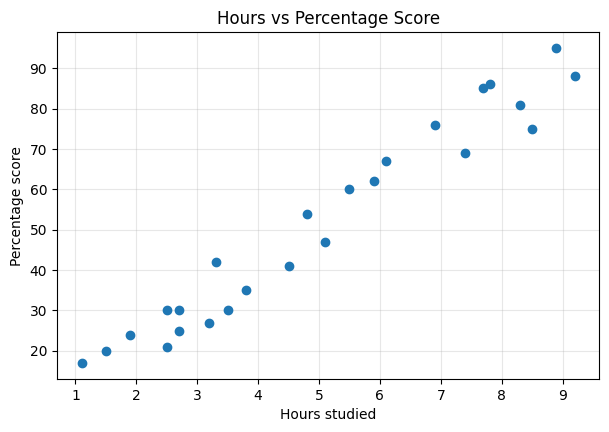

In [6]:
student.plot(x="Hours", y="Scores", style="o", figsize=(7, 4.5), legend=False)
plt.title("Hours vs Percentage Score")
plt.xlabel("Hours studied")
plt.ylabel("Percentage score")
plt.grid(alpha=.3)
plt.show()

**Observation:** the points rise almost along a straight line → a clear, strong positive linear relationship.

### Step 5 — Prepare the data: attributes (X) and label (y)
scikit-learn expects `X` as a **2-D** array (rows × features) and `y` as 1-D.

In [7]:
X = student[["Hours"]].values     # 2-D feature matrix
y = student["Scores"].values      # 1-D target
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (25, 1) | y shape: (25,)


### Step 6 — Split into training and test sets (80 % / 20 %)
`random_state` makes the split reproducible.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print("Training samples:", len(X_train))
print("Testing  samples:", len(X_test))

Training samples: 20
Testing  samples: 5


### Step 7 — Train the model

In [9]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("Training complete.")

Training complete.


### Step 8 — Inspect the learned parameters

In [10]:
print("Intercept (b0):", round(regressor.intercept_, 4))
print("Coefficient (b1):", round(regressor.coef_[0], 4))
print()
print(f"Equation:  Score = {regressor.intercept_:.2f} + {regressor.coef_[0]:.2f} × Hours")

Intercept (b0): 2.0182
Coefficient (b1): 9.9107

Equation:  Score = 2.02 + 9.91 × Hours


**Interpretation:** for every extra hour studied the score rises by about the coefficient value (≈ 9.9 points).

### Step 9 — Plot the fitted regression line

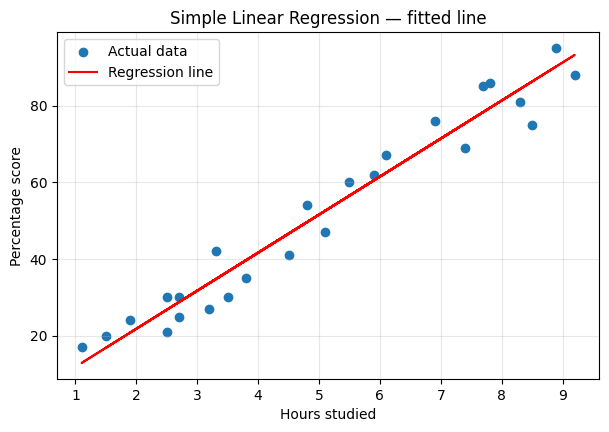

In [11]:
line = regressor.coef_ * X + regressor.intercept_
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, label="Actual data")
plt.plot(X, line, color="red", label="Regression line")
plt.title("Simple Linear Regression — fitted line")
plt.xlabel("Hours studied"); plt.ylabel("Percentage score")
plt.legend(); plt.grid(alpha=.3); plt.show()

### Step 10 — Make predictions on the test set

In [12]:
y_pred = regressor.predict(X_test)
comparison = pd.DataFrame({"Hours": X_test.ravel(), "Actual": y_test, "Predicted": y_pred.round(2)})
comparison["Error"] = (comparison["Actual"] - comparison["Predicted"]).round(2)
comparison

   Hours  Actual  Predicted  Error
0    1.5      20      16.88   3.12
1    3.2      27      33.73  -6.73
2    7.4      69      75.36  -6.36
3    2.5      30      26.79   3.21
4    5.9      62      60.49   1.51

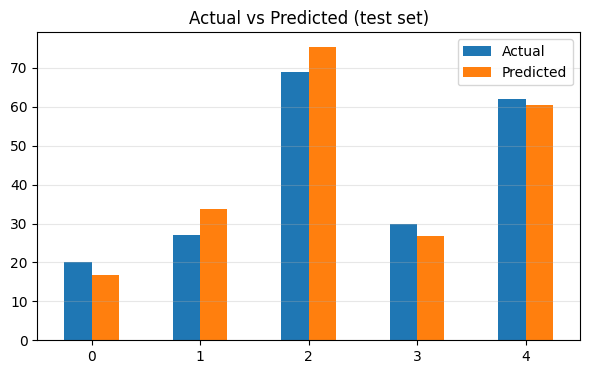

In [13]:
comparison[["Actual", "Predicted"]].plot(kind="bar", figsize=(7, 4))
plt.title("Actual vs Predicted (test set)")
plt.xticks(rotation=0); plt.grid(axis="y", alpha=.3); plt.show()

### Step 11 — Predict for new data
What score do we expect for **9.25 hours** of study?

In [14]:
own_pred = regressor.predict([[9.25]])
print("Hours studied      : 9.25")
print("Predicted score    :", round(own_pred[0], 2))

Hours studied      : 9.25
Predicted score    : 93.69


### Step 12 — Evaluate the model
| Metric | Meaning |
|---|---|
| **MAE** | average absolute error |
| **MSE** | average squared error (penalises big mistakes) |
| **RMSE** | square root of MSE, in the same unit as `y` |
| **R²** | proportion of variance explained (1 = perfect) |

In [15]:
mae  = metrics.mean_absolute_error(y_test, y_pred)
mse  = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = metrics.r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE) :", round(mae, 4))
print("Mean Squared Error  (MSE) :", round(mse, 4))
print("Root Mean Squared Error   :", round(rmse, 4))
print("R² score                  :", round(r2, 4))
print("Train R²                  :", round(regressor.score(X_train, y_train), 4))
print("Test  R²                  :", round(regressor.score(X_test, y_test), 4))

Mean Absolute Error (MAE) : 4.1839
Mean Squared Error  (MSE) : 21.5988
Root Mean Squared Error   : 4.6474
R² score                  : 0.9455
Train R²                  : 0.9516
Test  R²                  : 0.9455


**Conclusion (Part A):** R² is high and the RMSE is small compared with the 0–100 score range, so a straight line models this data very well.

# Part B — Multiple Linear Regression (several features)
**Problem:** predict **petrol consumption** (millions of gallons) in a US state from four features:

| Column | Meaning |
|---|---|
| `Petrol_tax` | petrol tax (cents) |
| `Average_income` | average income (dollars) |
| `Paved_Highways` | miles of paved highway |
| `Population_Driver_licence(%)` | share of the population with a driving licence |
| `Petrol_Consumption` | **target** |

The 48-row data is recreated here with the same columns (see the note at the top).

### Step 1 — Create / load the dataset

In [16]:
rng = np.random.default_rng(7)
n = 48
petrol = pd.DataFrame({
    "Petrol_tax":     np.round(rng.uniform(5, 10, n) * 2) / 2,
    "Average_income": rng.integers(3000, 5500, n),
    "Paved_Highways": rng.integers(400, 17000, n),
    "Population_Driver_licence(%)": np.round(rng.uniform(0.45, 0.70, n), 3),
})
petrol["Petrol_Consumption"] = (
    377 - 34.8*petrol["Petrol_tax"] - 0.0666*petrol["Average_income"]
    - 0.0024*petrol["Paved_Highways"] + 1336*petrol["Population_Driver_licence(%)"]
    + rng.normal(0, 55, n)
).round(0).astype(int)
petrol.to_csv("petrol_consumption.csv", index=False)

petrol = pd.read_csv("petrol_consumption.csv")
print("Shape:", petrol.shape)
petrol.head()

Shape: (48, 5)


   Petrol_tax  Average_income  Paved_Highways  Population_Driver_licence(%)  Petrol_Consumption
0         8.0            4816            8651                         0.456                 323
1         9.5            4269           14909                         0.543                 417
2         9.0            4532            1941                         0.458                 299
3         6.0            5178           11392                         0.481                 508
4         6.5            4715            9248                         0.692                 731

### Step 2 — Explore the data

In [17]:
petrol.describe().round(2)

       Petrol_tax  Average_income  Paved_Highways  Population_Driver_licence(%)  Petrol_Consumption
count       48.00           48.00           48.00                         48.00               48.00
mean         7.42         4197.67         9420.83                          0.58              583.02
std          1.47          664.31         4786.35                          0.07              127.62
min          5.00         3018.00         1031.00                          0.45              299.00
25%          6.00         3793.00         5575.75                          0.54              494.25
50%          7.50         4107.00         9655.50                          0.58              595.50
75%          8.62         4618.50        13386.25                          0.64              672.50
max         10.00         5446.00        16723.00                          0.70              863.00

In [18]:
print("Missing values:", petrol.isnull().sum().sum())
print()
print("Correlation of each feature with Petrol_Consumption:")
print(petrol.corr()["Petrol_Consumption"].drop("Petrol_Consumption").round(3))

Missing values: 0

Correlation of each feature with Petrol_Consumption:
Petrol_tax                     -0.226
Average_income                 -0.556
Paved_Highways                 -0.107
Population_Driver_licence(%)    0.754
Name: Petrol_Consumption, dtype: float64


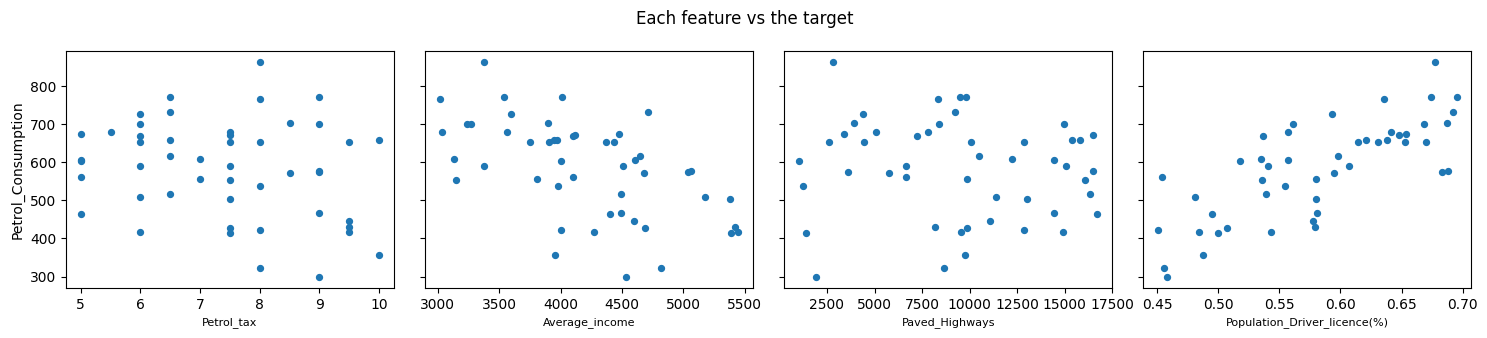

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, col in zip(axes, petrol.columns[:-1]):
    ax.scatter(petrol[col], petrol["Petrol_Consumption"], s=18)
    ax.set_xlabel(col, fontsize=8)
axes[0].set_ylabel("Petrol_Consumption")
fig.suptitle("Each feature vs the target"); plt.tight_layout(); plt.show()

### Step 3 — Attributes, labels and train/test split (80 / 20)

In [20]:
X = petrol[["Petrol_tax", "Average_income", "Paved_Highways", "Population_Driver_licence(%)"]]
y = petrol["Petrol_Consumption"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (38, 4) | Test: (10, 4)


### Step 4 — Train the multiple regression model

In [21]:
mreg = LinearRegression()
mreg.fit(X_train, y_train)
print("Intercept:", round(mreg.intercept_, 3))

Intercept: 396.633


### Step 5 — Coefficients
With several features, each coefficient shows the change in the target for a **one-unit increase of that feature, holding the others constant**.

In [22]:
coeff_df = pd.DataFrame(mreg.coef_, index=X.columns, columns=["Coefficient"])
coeff_df.round(4)

                              Coefficient
Petrol_tax                       -32.0628
Average_income                    -0.0766
Paved_Highways                    -0.0013
Population_Driver_licence(%)    1305.7433

**Reading the table:**
- A one-cent rise in petrol tax lowers consumption by roughly the (negative) `Petrol_tax` coefficient.
- A higher share of licensed drivers increases consumption — the largest effect per unit.
- `Average_income` and `Paved_Highways` have tiny coefficients simply because their values are in the thousands.

### Step 6 — Predict on the test set

In [23]:
y_pred = mreg.predict(X_test)
results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred.round(1)}, index=y_test.index)
results["Error"] = (results["Actual"] - results["Predicted"]).round(1)
results

    Actual  Predicted  Error
29     428      446.4  -18.4
4      731      719.0   12.0
26     672      666.5    5.5
30     414      394.2   19.8
32     464      524.3  -60.3
37     602      604.5   -2.5
34     702      717.9  -15.9
40     772      775.8   -3.8
7      468      504.3  -36.3
10     615      599.7   15.3

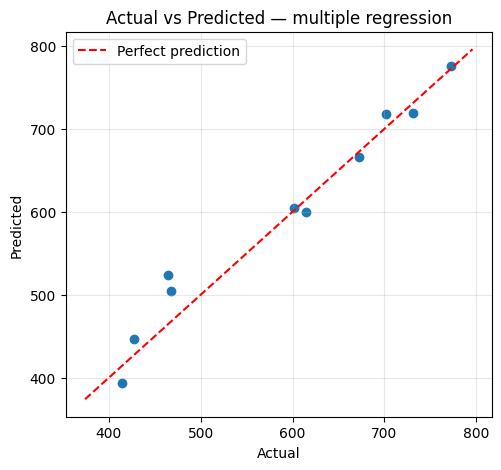

In [24]:
plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, y_pred)
lims = [min(y_test.min(), y_pred.min()) - 20, max(y_test.max(), y_pred.max()) + 20]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs Predicted — multiple regression")
plt.legend(); plt.grid(alpha=.3); plt.show()

### Step 7 — Evaluate the model

In [25]:
mae  = metrics.mean_absolute_error(y_test, y_pred)
mse  = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("Mean Absolute Error :", round(mae, 3))
print("Mean Squared Error  :", round(mse, 3))
print("Root Mean Sq. Error :", round(rmse, 3))
print("R² (test)           :", round(metrics.r2_score(y_test, y_pred), 4))
print()
print("Mean of Petrol_Consumption:", round(y.mean(), 2))
print("RMSE as % of the mean     :", round(rmse / y.mean() * 100, 2), "%")

Mean Absolute Error : 18.983
Mean Squared Error  : 636.685
Root Mean Sq. Error : 25.233
R² (test)           : 0.9604

Mean of Petrol_Consumption: 583.02
RMSE as % of the mean     : 4.33 %


---
# Week 5
## Topic: Machine Learning — Logistic Regression


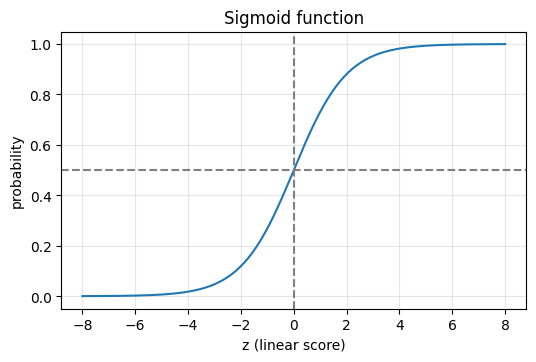

In [26]:
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))
plt.figure(figsize=(6, 3.6))
plt.plot(z, sigmoid)
plt.axhline(0.5, color="gray", ls="--"); plt.axvline(0, color="gray", ls="--")
plt.title("Sigmoid function"); plt.xlabel("z (linear score)"); plt.ylabel("probability")
plt.grid(alpha=.3); plt.show()

# Part A — Predicting Diabetes (DataCamp tutorial)
**Problem:** classify whether a patient has diabetes (`label` = 1) or not (0) from medical measurements — a **binary** classification.

| Column | Meaning |
|---|---|
| `pregnant` | number of pregnancies |
| `glucose` | plasma glucose concentration |
| `bp` | blood pressure |
| `skin` | skin-fold thickness |
| `insulin` | insulin level |
| `bmi` | body-mass index |
| `pedigree` | diabetes pedigree function |
| `age` | age (years) |
| `label` | **target** (0 = no diabetes, 1 = diabetes) |

### Step 1 — Import the classification tools

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, classification_report, roc_curve, roc_auc_score)

### Step 2 — Create / load the dataset (768 rows, Pima-style)

In [28]:
rng = np.random.default_rng(11)
n = 768
d = pd.DataFrame({
    "pregnant": rng.poisson(3.8, n),
    "glucose":  np.clip(rng.normal(121, 31, n), 44, 199).round(),
    "bp":       np.clip(rng.normal(69, 18, n), 24, 122).round(),
    "skin":     np.clip(rng.normal(21, 15, n), 0, 99).round(),
    "insulin":  np.clip(rng.lognormal(4.3, 0.9, n), 0, 846).round(),
    "bmi":      np.clip(rng.normal(32, 7.5, n), 18, 67).round(1),
    "pedigree": np.clip(rng.lognormal(-0.9, 0.6, n), 0.08, 2.4).round(3),
    "age":      np.clip(21 + rng.exponential(12, n), 21, 81).round(),
})
score = (-14.6 + 0.06*d.glucose + 0.11*d.bmi + 0.045*d.age
         + 0.18*d.pregnant + 1.6*d.pedigree)
d["label"] = (rng.random(n) < 1/(1 + np.exp(-score))).astype(int)
d.to_csv("diabetes.csv", index=False)

pima = pd.read_csv("diabetes.csv")
print("Shape:", pima.shape)
pima.head()

Shape: (768, 9)


   pregnant  glucose    bp  skin  insulin   bmi  pedigree   age  label
0         3     68.0  56.0  21.0     28.0  30.1     0.183  69.0      0
1         2    110.0  64.0  34.0    183.0  30.1     0.359  34.0      0
2         4    156.0  83.0  19.0     51.0  30.8     0.408  26.0      1
3         3    135.0  68.0   8.0     54.0  27.5     0.166  28.0      0
4         6     94.0  89.0  20.0     30.0  31.0     0.762  65.0      1

### Step 3 — Explore the data & check class balance

In [29]:
print(pima.describe().round(2))
print()
print("Class counts:")
print(pima["label"].value_counts())
print()
print("Share with diabetes:", round(pima["label"].mean() * 100, 1), "%")

       pregnant  glucose      bp    skin  insulin     bmi  pedigree     age   label
count    768.00   768.00  768.00  768.00   768.00  768.00    768.00  768.00  768.00
mean       3.69   121.72   68.72   23.14   112.88   31.95      0.49   32.71    0.40
std        1.90    29.66   17.87   14.76   114.41    7.25      0.33   11.12    0.49
min        0.00    44.00   24.00    0.00     4.00   18.00      0.08   21.00    0.00
25%        2.00   102.00   56.00   12.00    40.75   26.80      0.27   24.00    0.00
50%        3.00   121.00   69.00   22.00    75.00   31.90      0.40   29.00    0.00
75%        5.00   143.00   82.00   33.00   145.00   36.80      0.62   38.00    1.00
max       10.00   199.00  122.00   70.00   833.00   53.60      2.40   81.00    1.00

Class counts:
label
0    457
1    311
Name: count, dtype: int64

Share with diabetes: 40.5 %


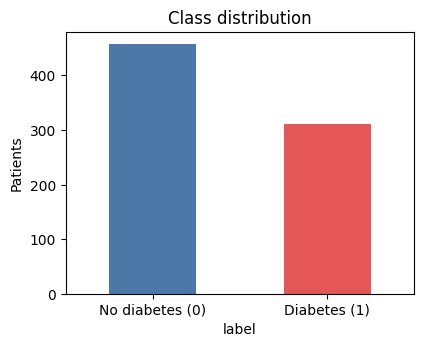

In [30]:
pima["label"].value_counts().plot(kind="bar", figsize=(4.5, 3.4), color=["#4C78A8", "#E45756"])
plt.title("Class distribution"); plt.xticks([0, 1], ["No diabetes (0)", "Diabetes (1)"], rotation=0)
plt.ylabel("Patients"); plt.show()

### Step 4 — Select features and split (75 % train / 25 % test)

In [31]:
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X = pima[feature_cols]
y = pima["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (576, 7) | Test: (192, 7)


### Step 5 — Build and train the model
`max_iter` is raised so the solver reliably converges on unscaled features.

In [32]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
print("Model trained.")
print("Intercept:", logreg.intercept_.round(3))

Model trained.
Intercept: [-16.707]


### Step 6 — Predict

In [33]:
y_pred = logreg.predict(X_test)
proba  = logreg.predict_proba(X_test)[:, 1]
print("First 10 predicted classes     :", y_pred[:10])
print("First 10 actual classes        :", y_test.values[:10])
print("First 10 predicted P(diabetes) :", proba[:10].round(3))

First 10 predicted classes     : [1 0 0 1 1 1 0 0 0 1]
First 10 actual classes        : [0 0 0 1 1 0 1 0 0 1]
First 10 predicted P(diabetes) : [0.54  0.033 0.016 0.558 0.97  0.673 0.04  0.135 0.146 0.824]


### Step 7 — Confusion matrix
|   | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | True Negative (TN) | False Positive (FP) |
| **Actual 1** | False Negative (FN) | True Positive (TP) |

In [34]:
cnf = confusion_matrix(y_test, y_pred)
print(cnf)

[[92 26]
 [19 55]]


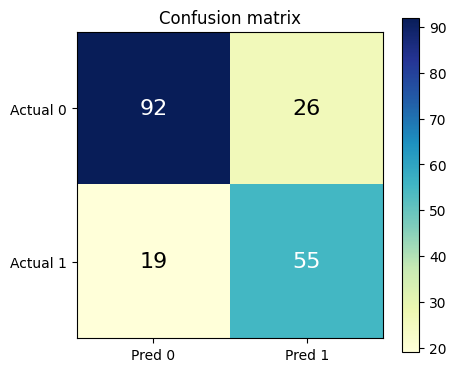

In [35]:
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cnf, cmap="YlGnBu")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred 0", "Pred 1"]); ax.set_yticklabels(["Actual 0", "Actual 1"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cnf[i, j], ha="center", va="center", fontsize=16,
                color="white" if cnf[i, j] > cnf.max()/2 else "black")
ax.set_title("Confusion matrix"); plt.colorbar(im); plt.tight_layout(); plt.show()

### Step 8 — Accuracy, precision and recall

In [36]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"]))

Accuracy : 0.7656
Precision: 0.679
Recall   : 0.7432

              precision    recall  f1-score   support

 No diabetes       0.83      0.78      0.80       118
    Diabetes       0.68      0.74      0.71        74

    accuracy                           0.77       192
   macro avg       0.75      0.76      0.76       192
weighted avg       0.77      0.77      0.77       192



**How to read these:**
- **Accuracy** – share of all predictions that were right.
- **Precision** – of the patients predicted diabetic, how many truly are.
- **Recall** – of the truly diabetic patients, how many the model found (very important in medical screening).

### Step 9 — ROC curve and AUC
The ROC curve plots the true-positive rate against the false-positive rate for every decision threshold. The closer the curve hugs the top-left corner (AUC → 1), the better.

AUC: 0.8183


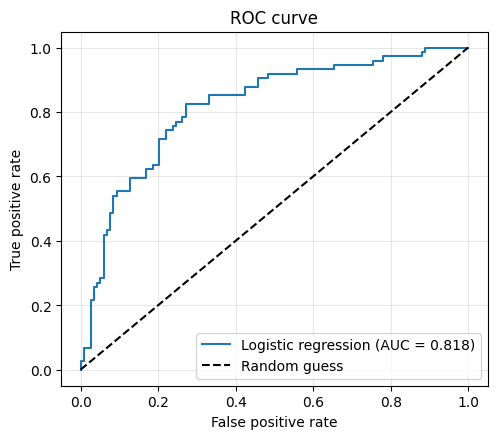

In [37]:
fpr, tpr, thresholds = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
plt.figure(figsize=(5.5, 4.6))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve"); plt.legend(loc=4); plt.grid(alpha=.3); plt.show()
print("AUC:", round(auc, 4))

### Step 10 — Which features matter? Coefficients & odds ratios
A positive coefficient raises the log-odds of diabetes. `exp(coef)` is the **odds ratio** per one-unit increase.

In [38]:
coefs = pd.DataFrame({"Coefficient": logreg.coef_[0],
                      "Odds ratio": np.exp(logreg.coef_[0])}, index=feature_cols)
coefs.sort_values("Coefficient", ascending=False).round(4)

          Coefficient  Odds ratio
pedigree       1.9737      7.1969
pregnant       0.1950      1.2153
bmi            0.1255      1.1337
glucose        0.0714      1.0740
age            0.0587      1.0604
insulin       -0.0008      0.9992
bp            -0.0026      0.9974

### Step 11 — Predict for a new patient

In [39]:
new_patient = pd.DataFrame([{"pregnant": 2, "insulin": 120, "bmi": 33.0, "age": 45,
                             "glucose": 150, "bp": 72, "pedigree": 0.6}])
p = logreg.predict_proba(new_patient)[0, 1]
print(f"Probability of diabetes: {p:.3f}")
print("Predicted class        :", int(logreg.predict(new_patient)[0]),
      "(1 = diabetes)")

Probability of diabetes: 0.889
Predicted class        : 1 (1 = diabetes)


**Conclusion (Part A):** the model separates the two classes well (see accuracy and AUC above). Accuracy alone does not tell the whole story: the diabetic class is the minority (about 40 % of patients) and its precision and recall are lower than for the healthy class, and in medical screening missed cases (false negatives) matter most. Coefficients are on different scales (e.g. `pedigree` is 0–2.4 while `insulin` is in hundreds), so compare them with caution unless the features are standardised.

# Part B — Handwritten Digit Recognition (Towards Data Science tutorial)
**Problem:** recognise the digit (0–9) in an image — a **multiclass** classification.

The tutorial uses MNIST-style handwriting. We use scikit-learn's built-in `load_digits()` — a compact 8×8-pixel version (1,797 images) that needs no download. The workflow is identical to the full 28×28 MNIST.

### Step 1 — Load the digits dataset

In [40]:
from sklearn.datasets import load_digits
digits = load_digits()
print("Image data shape :", digits.data.shape, "(samples × 64 pixels)")
print("Label data shape :", digits.target.shape)
print("Image array shape:", digits.images.shape, "(samples × 8 × 8)")
print("Classes          :", np.unique(digits.target))

Image data shape : (1797, 64) (samples × 64 pixels)
Label data shape : (1797,)
Image array shape: (1797, 8, 8) (samples × 8 × 8)
Classes          : [0 1 2 3 4 5 6 7 8 9]


### Step 2 — Look at some images

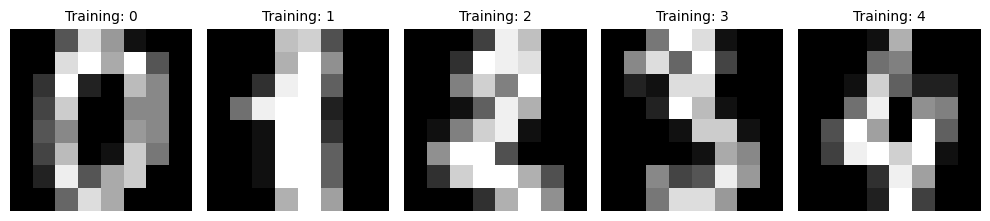

In [41]:
plt.figure(figsize=(10, 2.6))
for i, (img, lab) in enumerate(zip(digits.images[:5], digits.target[:5])):
    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap=plt.cm.gray)
    plt.title(f"Training: {lab}", fontsize=10)
    plt.axis("off")
plt.tight_layout(); plt.show()

In [42]:
print("Samples per digit:")
print(pd.Series(digits.target).value_counts().sort_index().to_string())

Samples per digit:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180


### Step 3 — Split the data (75 % / 25 %)

In [43]:
x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target,
                                                    test_size=0.25, random_state=0)
print("x_train:", x_train.shape, "| x_test:", x_test.shape)

x_train: (1347, 64) | x_test: (450, 64)


### Step 4 — Train the logistic regression model

In [44]:
digit_model = LogisticRegression(max_iter=10000)
digit_model.fit(x_train, y_train)
print("Model trained. Coefficient matrix shape:", digit_model.coef_.shape,
      "(one row of weights per digit class)")

Model trained. Coefficient matrix shape: (10, 64) (one row of weights per digit class)


### Step 5 — Predict single and multiple images

In [45]:
print("Predicted digit for test image 0 :", digit_model.predict(x_test[0].reshape(1, -1))[0],
      "| actual:", y_test[0])
print("Predictions for first 10 images :", digit_model.predict(x_test[:10]))
print("Actual labels                   :", y_test[:10])

Predicted digit for test image 0 : 2 | actual: 2
Predictions for first 10 images : [2 8 2 6 6 7 1 9 8 5]
Actual labels                   : [2 8 2 6 6 7 1 9 8 5]


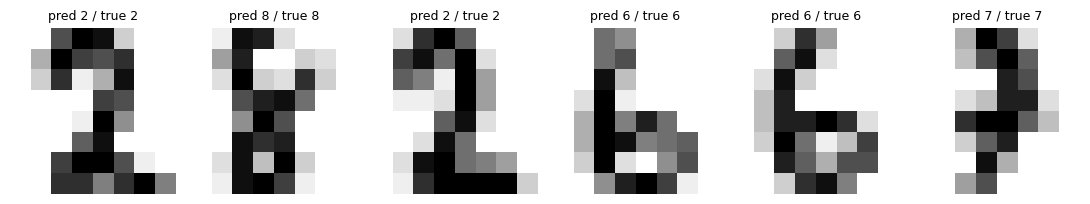

In [46]:
predictions = digit_model.predict(x_test)
fig, axes = plt.subplots(1, 6, figsize=(11, 2.4))
for ax, img, p, a in zip(axes, x_test[:6], predictions[:6], y_test[:6]):
    ax.imshow(img.reshape(8, 8), cmap=plt.cm.gray_r); ax.axis("off")
    ax.set_title(f"pred {p} / true {a}", fontsize=9)
plt.tight_layout(); plt.show()

### Step 6 — Measure accuracy

In [47]:
score = digit_model.score(x_test, y_test)
print("Test accuracy :", round(score, 4), f"({score*100:.2f} %)")
print("Train accuracy:", round(digit_model.score(x_train, y_train), 4))

Test accuracy : 0.9533 (95.33 %)
Train accuracy: 1.0


### Step 7 — Confusion matrix (10 × 10)
Rows are actual digits, columns are predicted digits. A perfect model has numbers only on the diagonal.

In [48]:
cm = confusion_matrix(y_test, predictions)
print(cm)

[[37  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  2  1]
 [ 0  0 41  3  0  0  0  0  0  0]
 [ 0  0  0 43  0  0  0  0  1  1]
 [ 0  0  0  0 37  0  0  1  0  0]
 [ 0  0  0  0  0 46  0  0  0  2]
 [ 0  1  0  0  0  0 51  0  0  0]
 [ 0  0  0  1  1  0  0 46  0  0]
 [ 0  3  1  0  0  0  0  0 43  1]
 [ 0  0  0  0  0  1  0  0  1 45]]


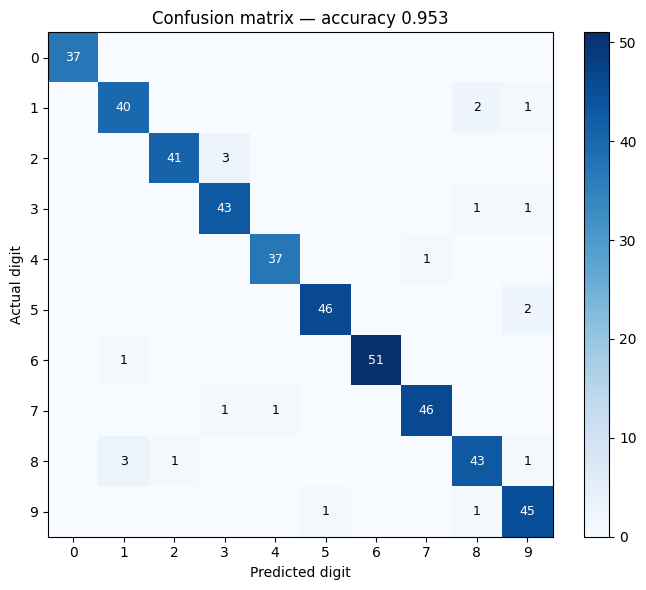

In [49]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Predicted digit"); ax.set_ylabel("Actual digit")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_title(f"Confusion matrix — accuracy {score:.3f}")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

### Step 8 — Per-class report

In [50]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       0.91      0.93      0.92        43
           2       0.98      0.93      0.95        44
           3       0.91      0.96      0.93        45
           4       0.97      0.97      0.97        38
           5       0.98      0.96      0.97        48
           6       1.00      0.98      0.99        52
           7       0.98      0.96      0.97        48
           8       0.91      0.90      0.91        48
           9       0.90      0.96      0.93        47

    accuracy                           0.95       450
   macro avg       0.95      0.95      0.95       450
weighted avg       0.95      0.95      0.95       450



### Step 9 — Look at the misclassified images
Seeing the mistakes helps us understand the model's weaknesses.

Misclassified: 21 out of 450


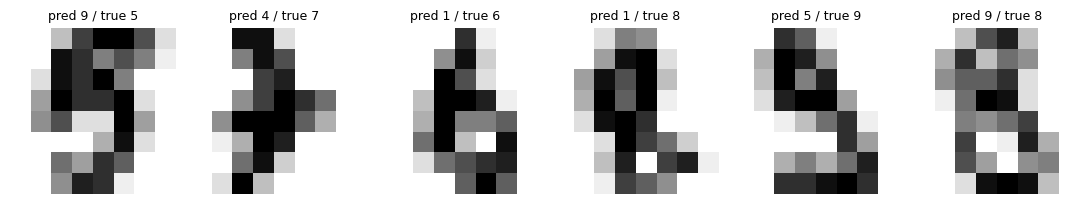

In [51]:
wrong = np.where(predictions != y_test)[0]
print("Misclassified:", len(wrong), "out of", len(y_test))
fig, axes = plt.subplots(1, min(6, len(wrong)), figsize=(11, 2.6))
for ax, idx in zip(np.atleast_1d(axes), wrong[:6]):
    ax.imshow(x_test[idx].reshape(8, 8), cmap=plt.cm.gray_r); ax.axis("off")
    ax.set_title(f"pred {predictions[idx]} / true {y_test[idx]}", fontsize=9)
plt.tight_layout(); plt.show()